# Tester l'OCR sur les zones détectées par le modèle `champion`

**Quand ?** Jour 2, une fois le modèle `champion` de votre squad enregistré dans MLflow.

**Quoi ?** Ce notebook :

1. télécharge le modèle ONNX `flexistaff_<squad>@champion` depuis le registre MLflow ;
2. détecte les zones (avec **vos** classes) sur quelques images ;
3. lance EasyOCR sur chaque zone détectée, avec les mêmes réglages que l'application CalEvent ;
4. résume ce qui est lu, classe par classe, et sauvegarde le tout dans `ocr_<alias>.json`.
5. mesure le rappel et la mAP50 du modèle sur le **jeu de test noté** de votre squad (section 11).

**Pourquoi ?** Pour préparer le **parsing** du jour 3 : voir concrètement ce que l'OCR lit dans vos zones,
quelles classes portent la date, l'heure, le titre, et quelles erreurs il faudra corriger.

**Prérequis**

- le fichier `identifiants-<login>.json` téléchargé depuis le portail (à déposer dans Colab : panneau *Fichiers*) ;
- un modèle enregistré sous `flexistaff_<squad>` avec l'alias `champion` ;
- rien d'autre : le jeu d'images de test commun (photos de plannings jamais vues à l'entraînement) est
  téléchargé automatiquement depuis la release GitHub du projet. Vous pouvez aussi tester vos propres images.

> Sur Colab, activez un GPU (*Exécution → Modifier le type d'exécution*) : EasyOCR sera beaucoup plus rapide.

## 1. Installation

In [1]:
%pip install -q ultralytics mlflow onnx onnxruntime onnxslim easyocr

## 2. Paramètres

Adaptez ces valeurs à votre squad. `IMAGES` peut être un dossier **ou** une seule image.

In [5]:
CREDENTIALS = "identifiants-carole.n.json"  # fichier téléchargé depuis le portail
SQUAD = "team-rocket"                      # team-rocket, team-magma ou team-aqua
ALIAS = "champion"                         # puis "challenger" pour comparer
IMAGES = "test_ocr"                        # jeu de test commun (téléchargé ci-dessous) ; ou votre dossier / image
CONF = 0.25                                # seuil de confiance de la détection YOLO
MAX_IMAGES = 10                            # nombre d'images traitées (OCR lent sur CPU) ; None = toutes, avec un GPU
OCR_MIN_CONF = 0.4                         # lignes OCR sous ce seuil ignorées (comme dans CalEvent)
CLASSES_OCR = None                         # None = OCR sur toutes vos classes ; ou une liste, ex. ["event"]

MODEL_NAME = f"flexistaff_{SQUAD}"

# Jeu de test commun : le même pour toutes les squads, jamais utilisé pour l'entraînement
TEST_ZIP_URL = "https://github.com/CassiaFa/flexistaff/releases/download/test-ocr-v1/test_ocr.zip"

### Jeu d'images de test

Le jeu commun est téléchargé une seule fois (dossier `test_ocr/`). Comparer les modèles sur les **mêmes** images, jamais vues à l'entraînement, rend la comparaison champion / challenger (et entre squads) équitable.

In [3]:
import urllib.request, zipfile
from pathlib import Path

if IMAGES == "test_ocr" and not Path("test_ocr").is_dir():
    urllib.request.urlretrieve(TEST_ZIP_URL, "test_ocr.zip")
    with zipfile.ZipFile("test_ocr.zip") as z:
        z.extractall(".")
print(f"Images : {IMAGES} ({len(list(Path(IMAGES).glob('*')))} fichiers)")


Images : test_ocr (20 fichiers)


## 3. Connexion à MLflow et téléchargement du modèle

Les identifiants sont lus dans le fichier JSON et passés par variables d'environnement :
ils ne sont **jamais** affichés.

In [6]:
import json
import os
from pathlib import Path

import mlflow
from mlflow.tracking import MlflowClient

with open(CREDENTIALS, encoding="utf-8") as f:
    creds = json.load(f)["mlflow"]
os.environ["MLFLOW_TRACKING_USERNAME"] = creds["username"]
os.environ["MLFLOW_TRACKING_PASSWORD"] = creds["password"]
mlflow.set_tracking_uri(creds["tracking_uri"])

# Quelle version porte l'alias, et de quel run vient-elle ?
client = MlflowClient()
version = client.get_model_version_by_alias(MODEL_NAME, ALIAS)
run_name = client.get_run(version.run_id).info.run_name if version.run_id else "?"
print(f"Modèle : {MODEL_NAME}@{ALIAS} → version {version.version} (run « {run_name} »)")

# Téléchargement : un dossier qui contient model.onnx
model_dir = Path(f"modele_{ALIAS}")
mlflow.artifacts.download_artifacts(f"models:/{MODEL_NAME}@{ALIAS}", dst_path=str(model_dir))
onnx_files = sorted(model_dir.rglob("*.onnx"))
if not onnx_files:
    raise FileNotFoundError(f"Aucun fichier .onnx trouvé dans {model_dir}")
onnx_path = onnx_files[0]
print("Fichier ONNX :", onnx_path)

Modèle : flexistaff_team-rocket@champion → version 1 (run « malgorzata_v1 »)


Fichier ONNX : modele_champion/model.onnx


## 4. Chargement du modèle et de ses classes

Ultralytics enregistre les noms des classes dans les métadonnées du fichier ONNX.

In [7]:
from ultralytics import YOLO

model = YOLO(str(onnx_path), task="detect")
# model.names n'est rempli qu'au premier predict pour un modèle ONNX : on lance une
# prédiction « à blanc » sur une image noire pour charger les métadonnées.
import numpy as np
model.predict(np.zeros((640, 640, 3), dtype=np.uint8), imgsz=640, verbose=False)

print("Classes du modèle :")
for idx, nom in model.names.items():
    print(f"  {idx} : {nom}")

if all(str(nom).startswith("class") for nom in model.names.values()):
    print("\n⚠ Noms génériques (class0, class1…) : les métadonnées sont absentes du fichier ONNX.\n"
          "  Retrouvez les vrais noms dans le data.yaml de votre dataset (clé « names »).")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Loading modele_champion/model.onnx for ONNX Runtime inference...
requirements: Ultralytics requirement ['onnxruntime-gpu[cuda]'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 10 packages in 217ms
Prepared 1 package in 2.83s
Installed 1 package in 26ms
 + onnxruntime-gpu==1.32.0

requirements: AutoUpdate success ✅ 3.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Using ONNX Runtime 1.32.0 with CUDAExecutionProvider
Classes du modèle :
  0 : Titre_calendrier
  1 : Date_case
  2 : Ressource
  3 : Evenement


## 5. Lecteur OCR (mêmes réglages que l'application CalEvent)

On reproduit les réglages de `calevent/backend/app/services/ocr.py` :

- langues `fr` et `en` ;
- prétraitement de chaque zone : niveaux de gris, agrandissement si la zone fait moins de 64 px de haut,
  marge de 8 px autour (pour ne pas couper le texte collé au bord) ;
- paramètres de `readtext` abaissés pour ne pas rater les petits numéros de jour ;
- lignes de confiance inférieure à `OCR_MIN_CONF` ignorées (et comptées), puis tri dans l'ordre de lecture.

Différence avec l'application : CalEvent ne lit que certaines de **ses** classes. Ici, vous avez vos propres
classes, donc l'OCR est lancé sur **toutes** les zones détectées (sauf si vous restreignez avec `CLASSES_OCR`).

Le premier lancement télécharge les modèles EasyOCR (~100 Mo).

In [8]:
import cv2
import easyocr
import torch

MIN_CROP_HEIGHT = 64  # hauteur minimale d'une zone avant OCR (px)
PADDING = 8           # marge ajoutée autour de la zone (px)
READTEXT_KWARGS = {"mag_ratio": 2, "min_size": 5, "low_text": 0.3, "text_threshold": 0.5}

gpu = torch.cuda.is_available()
reader = easyocr.Reader(["fr", "en"], gpu=gpu, verbose=False)
print("EasyOCR prêt, GPU :", gpu)


def pretraiter(crop):
    # Niveaux de gris + agrandissement des petites zones + marge
    gris = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY) if crop.ndim == 3 else crop
    h = gris.shape[0]
    if h < MIN_CROP_HEIGHT:
        echelle = MIN_CROP_HEIGHT / h
        gris = cv2.resize(gris, None, fx=echelle, fy=echelle, interpolation=cv2.INTER_CUBIC)
    return cv2.copyMakeBorder(gris, PADDING, PADDING, PADDING, PADDING, cv2.BORDER_REPLICATE)


def lire_zone(crop):
    # Renvoie (texte, confiance moyenne, nb de lignes ignorées) ; texte "" et confiance None si rien n'est lu
    if crop.size == 0:
        return "", None, 0
    resultats = reader.readtext(pretraiter(crop), **READTEXT_KWARGS)
    # resultats : liste de (4 points du polygone, texte, confiance)
    lignes = []
    nb_ignorees = 0
    for points, texte, conf in resultats:
        texte = texte.strip()
        if not texte:
            continue
        if conf < OCR_MIN_CONF:
            nb_ignorees += 1  # ligne lue, mais trop peu sûre
            continue
        ys = [p[1] for p in points]
        xs = [p[0] for p in points]
        lignes.append({"texte": texte, "conf": float(conf),
                       "cy": (min(ys) + max(ys)) / 2, "h": max(ys) - min(ys), "x": min(xs)})
    if not lignes:
        return "", None, nb_ignorees
    # Ordre de lecture : on regroupe par ligne visuelle (haut → bas), puis gauche → droite
    lignes.sort(key=lambda l: l["cy"])
    h_moy = sum(l["h"] for l in lignes) / len(lignes)
    rangees = [[lignes[0]]]
    for l in lignes[1:]:
        if abs(l["cy"] - rangees[-1][-1]["cy"]) <= h_moy / 2:
            rangees[-1].append(l)
        else:
            rangees.append([l])
    ordre = [l for r in rangees for l in sorted(r, key=lambda l: l["x"])]
    texte = " ".join(l["texte"] for l in ordre)
    conf = sum(l["conf"] for l in ordre) / len(ordre)
    return texte, round(conf, 3), nb_ignorees

EasyOCR prêt, GPU : True


## 6. Détection + OCR sur les images

Pour chaque image : détection YOLO, découpe de chaque zone, OCR, puis affichage de l'image annotée
et d'un tableau des zones.

10 image(s) à traiter


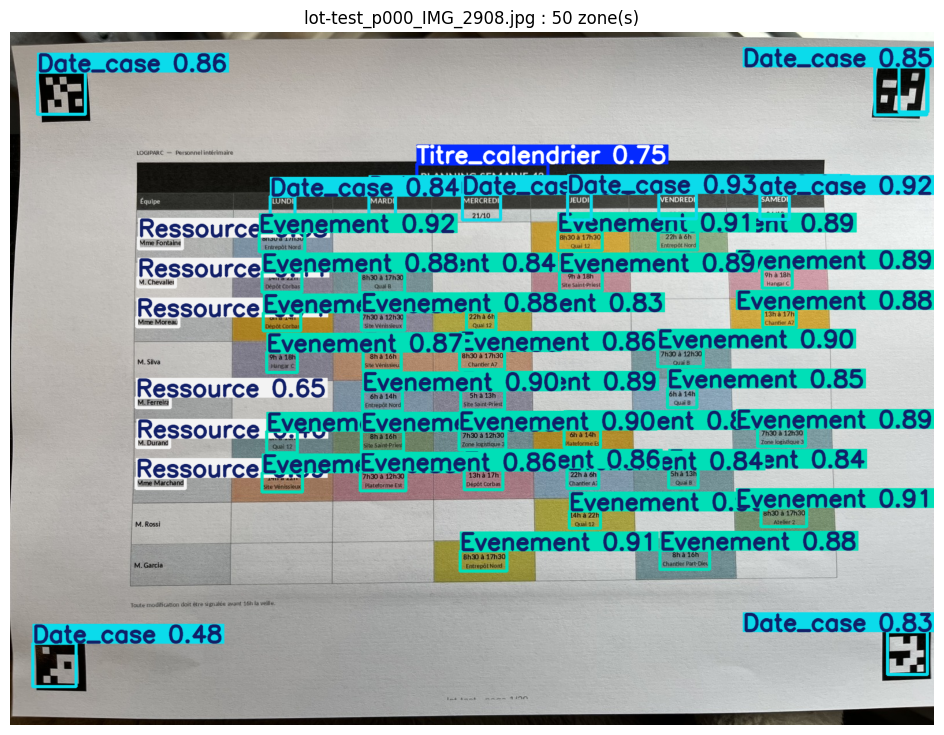

,classe,confiance_detection,x1,y1,x2,y2,texte,confiance_ocr,lignes_ignorees
49,Date_case,0.275,1539,59,1589,138,,NaN,0
30,Date_case,0.854,1497,60,1587,143,,NaN,0
27,Date_case,0.861,47,69,130,142,,NaN,0
41,Titre_calendrier,0.754,704,228,931,262,PLANNING SEMAINE 43,0.632,0
0,Date_case,0.926,965,279,1006,325,Jeudi 22/10,0.569,0
4,Date_case,0.912,1123,279,1188,323,VENDREDI 23/10,0.891,0
39,Date_case,0.830,621,281,667,326,MARDI 20/10,0.732,0
5,Date_case,0.911,783,281,849,325,21/10,0.797,1
2,Date_case,0.916,1298,281,1349,324,SAMEDI 24/10,0.888,0
37,Date_case,0.836,450,284,493,327,LUNDI 19/10,0.909,0


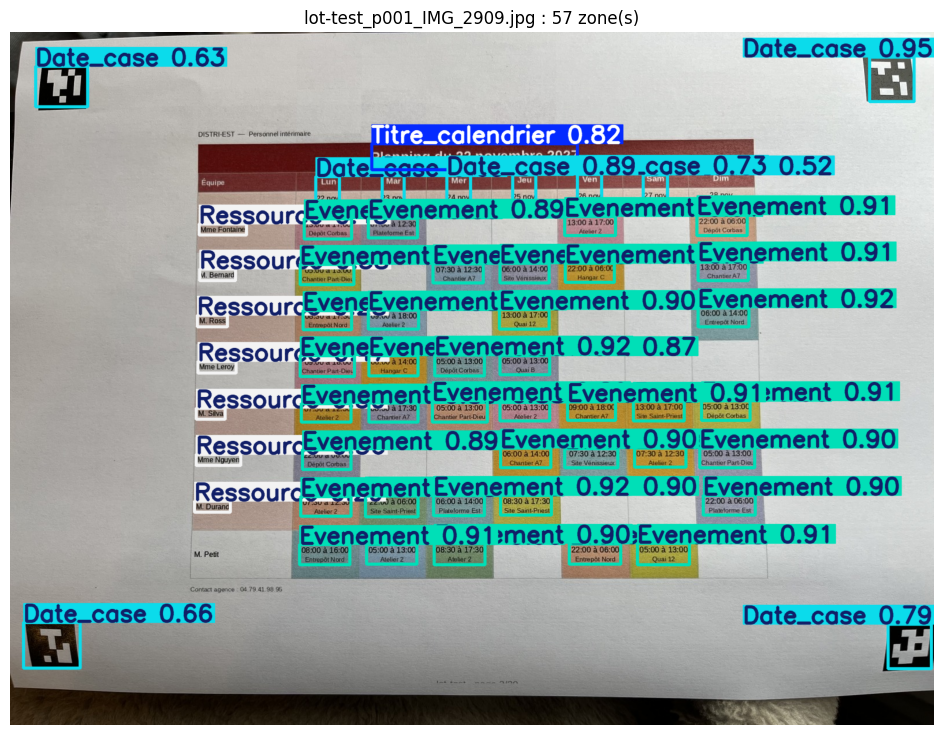

,classe,confiance_detection,x1,y1,x2,y2,texte,confiance_ocr,lignes_ignorees
0,Date_case,0.948,1488,43,1565,120,,NaN,0
46,Date_case,0.632,44,59,134,129,,NaN,0
41,Titre_calendrier,0.817,626,193,982,238,Planning du 22 novembre 2027,0.933,0
43,Date_case,0.726,982,246,1024,292,Ven 26 nov,0.998,0
27,Date_case,0.887,756,247,797,295,Mer 24 nov,0.934,0
48,Date_case,0.589,870,247,910,292,Jeu 25 nov,0.938,0
50,Date_case,0.520,1096,247,1138,291,Sam 27 nov,0.999,0
47,Date_case,0.609,644,248,682,296,Mar 723 nov,0.739,0
44,Date_case,0.695,529,250,570,296,Lun 22 nov,0.990,0
5,Evenement,0.913,1189,316,1276,352,22.00 à 06.00,0.797,1


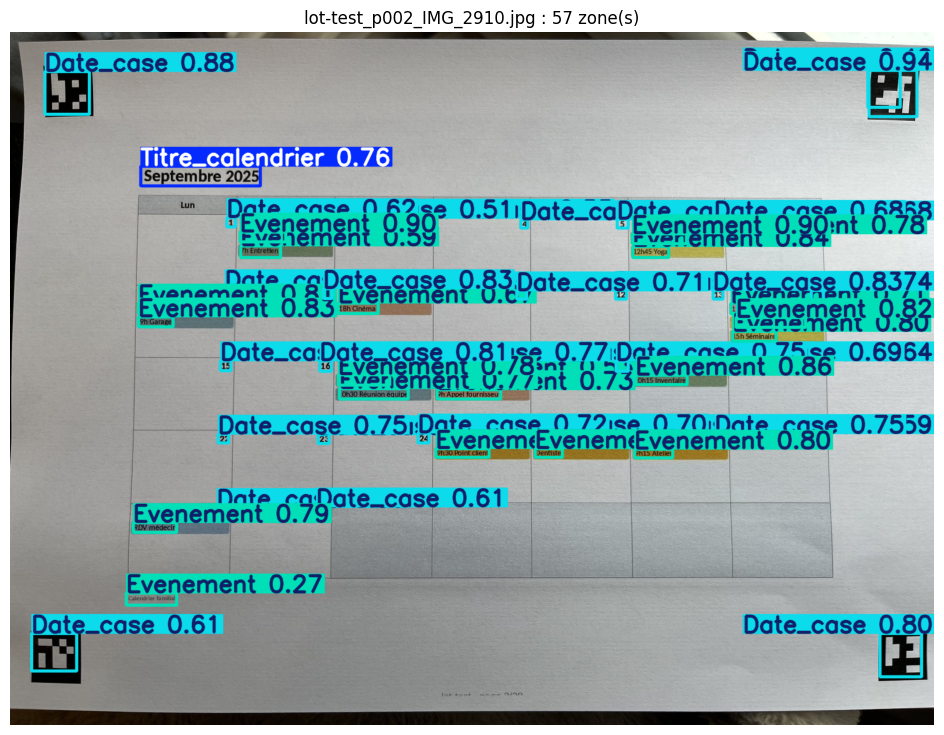

,classe,confiance_detection,x1,y1,x2,y2,texte,confiance_ocr,lignes_ignorees
54,Date_case,0.423,1485,60,1541,130,,NaN,0
0,Date_case,0.940,1487,66,1570,146,,NaN,0
3,Date_case,0.878,60,68,137,142,,NaN,1
22,Titre_calendrier,0.762,226,232,433,266,Septembre 2025,0.910,0
41,Date_case,0.625,375,321,390,337,1,1.000,0
52,Date_case,0.512,543,322,557,338,2,1.000,0
55,Date_case,0.326,715,322,730,338,3,1.000,0
49,Date_case,0.543,1051,324,1070,339,5,1.000,0
35,Date_case,0.684,1219,324,1233,340,6,1.000,0
51,Date_case,0.524,884,325,896,339,4,1.000,0


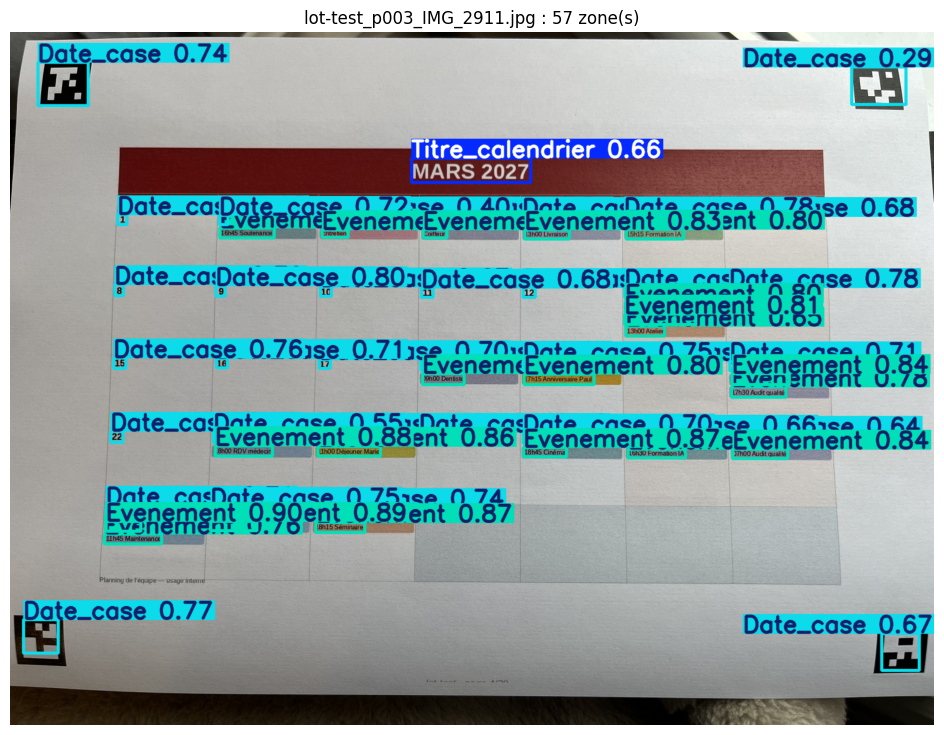

,classe,confiance_detection,x1,y1,x2,y2,texte,confiance_ocr,lignes_ignorees
29,Date_case,0.737,48,52,135,127,,NaN,0
56,Date_case,0.293,1457,60,1551,125,,NaN,0
44,Titre_calendrier,0.655,695,218,901,260,MARS 2027,0.990,0
46,Date_case,0.650,186,316,202,333,1,1.000,0
31,Date_case,0.724,362,317,377,333,2,1.000,0
52,Date_case,0.398,538,318,551,332,3,1.000,0
55,Date_case,0.345,713,318,730,335,4,1.000,0
16,Date_case,0.781,1063,318,1078,336,6,1.000,0
21,Date_case,0.766,887,319,902,336,5,1.000,0
40,Date_case,0.676,1238,319,1252,336,7,1.000,0


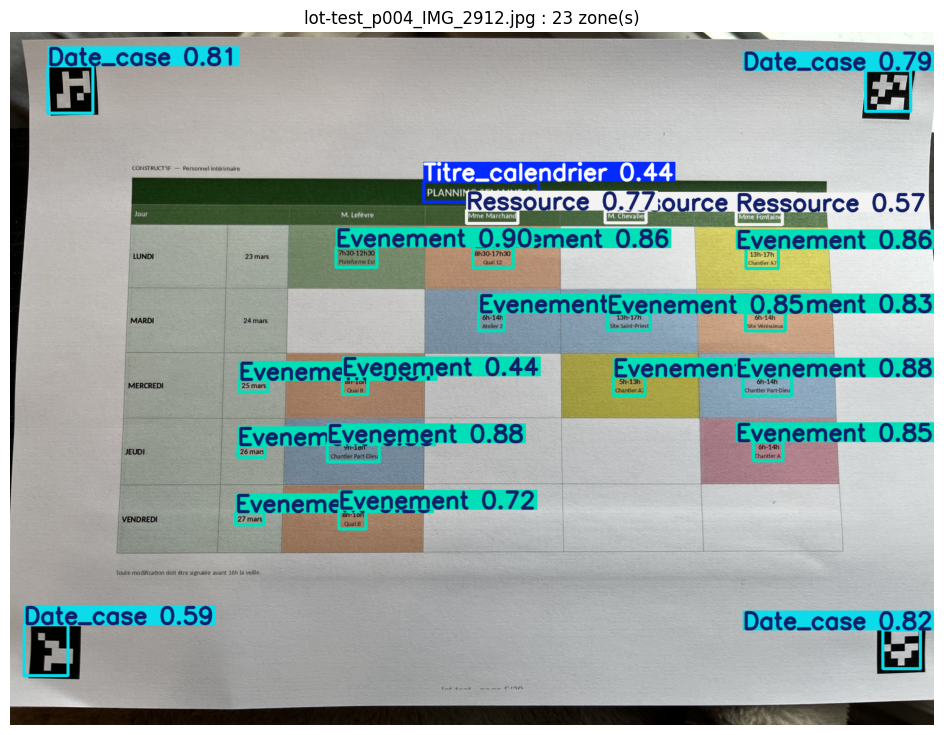

,classe,confiance_detection,x1,y1,x2,y2,texte,confiance_ocr,lignes_ignorees
10,Date_case,0.806,65,58,143,140,,NaN,1
11,Date_case,0.794,1481,66,1559,137,,NaN,0
17,Titre_calendrier,0.441,716,258,915,294,PLANNING SEMAINE 13,0.606,0
12,Ressource,0.773,790,308,879,331,Mme Marchand,0.947,0
21,Ressource,0.298,1030,310,1101,330,M Chevalier,0.871,0
16,Ressource,0.572,1257,311,1337,333,Mme Fontaine,0.997,0
0,Evenement,0.901,564,372,635,407,7h30-12h30 Plateforma Est,0.763,0
4,Evenement,0.859,801,373,871,408,8h30-17h30 (Qual 12,0.780,0
3,Evenement,0.860,1274,375,1330,409,13h-17h Chantier A7,0.859,0
13,Evenement,0.734,811,486,855,517,6h-14h Ateller 2,0.770,0


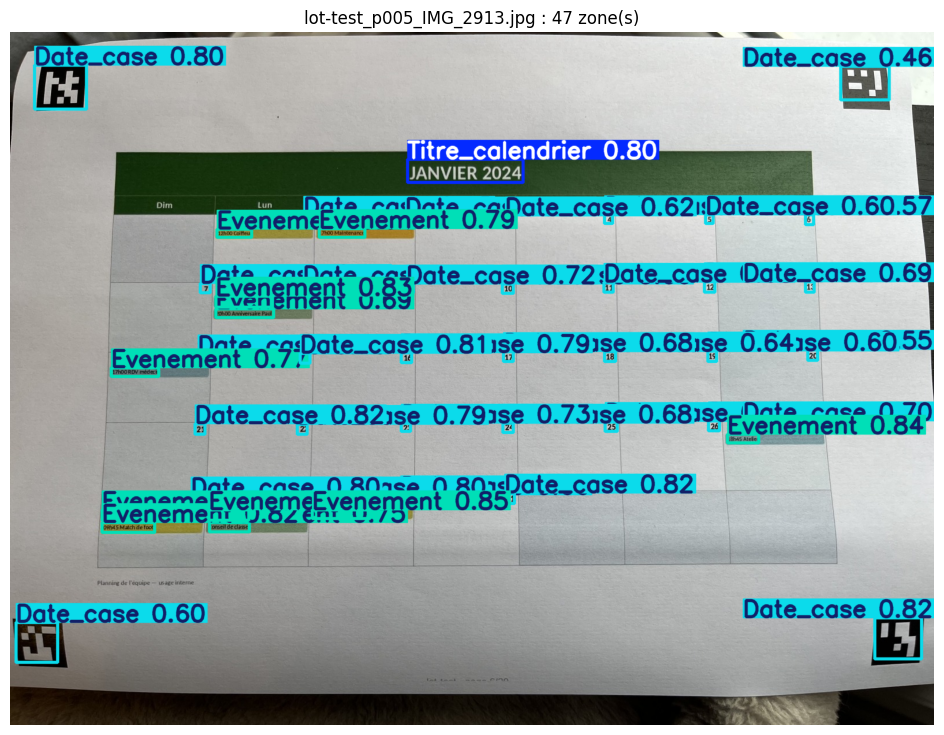

,classe,confiance_detection,x1,y1,x2,y2,texte,confiance_ocr,lignes_ignorees
11,Date_case,0.804,42,57,132,133,,NaN,1
43,Date_case,0.462,1438,59,1522,117,,NaN,0
12,Titre_calendrier,0.800,688,220,888,260,JANVIER 2024,0.720,0
45,Date_case,0.442,1029,316,1043,331,4,1.000,0
37,Date_case,0.597,1204,316,1217,331,5,1.000,0
40,Date_case,0.567,1377,316,1391,333,6,1.000,0
44,Date_case,0.446,508,317,522,334,1,1.000,0
39,Date_case,0.570,684,318,697,332,2,1.000,0
35,Date_case,0.620,857,318,871,333,3,1.000,0
15,Evenement,0.790,535,340,614,355,,NaN,1


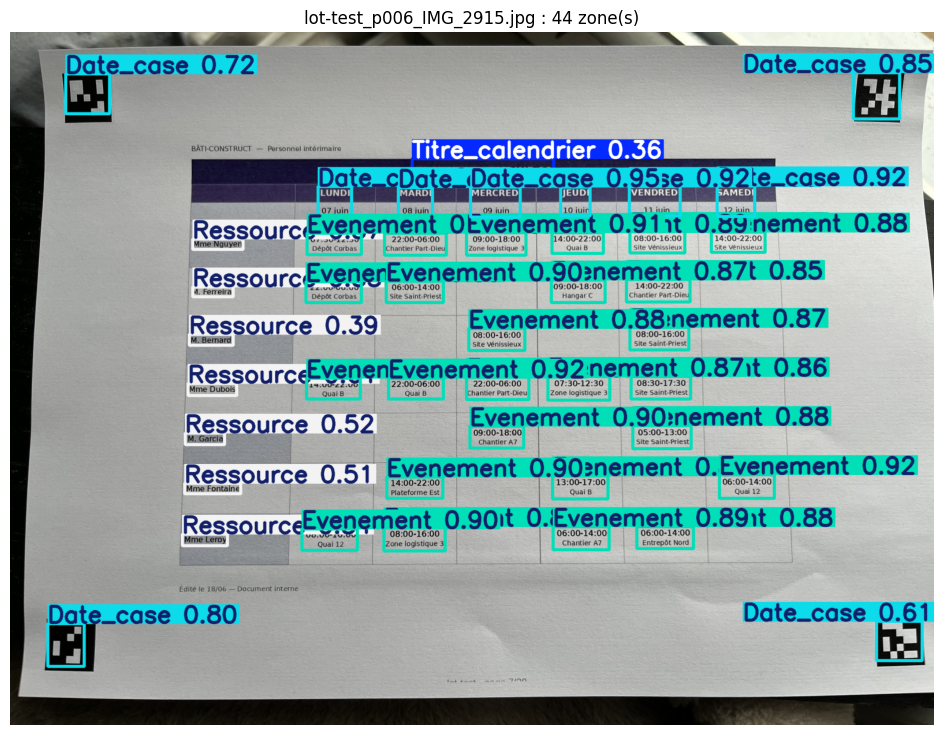

,classe,confiance_detection,x1,y1,x2,y2,texte,confiance_ocr,lignes_ignorees
31,Date_case,0.848,1460,70,1540,150,,NaN,1
34,Date_case,0.719,96,72,172,141,,NaN,0
42,Titre_calendrier,0.364,696,219,941,260,PLANNING SEMAINE 23,0.729,0
4,Date_case,0.919,1224,266,1289,319,SAMEDI 12 juin,0.846,0
27,Date_case,0.864,533,267,591,319,LUNDI 07 juin,0.964,0
10,Date_case,0.899,1072,267,1160,318,VENDRED 11 juin,0.993,0
0,Date_case,0.954,797,268,883,320,MERCRED 09 juin,0.998,0
1,Date_case,0.923,953,268,1004,318,JEUDI 10 juin,0.979,0
23,Date_case,0.869,672,269,731,320,MARDI 08 juin,0.788,0
22,Evenement,0.871,1073,345,1168,382,08.00-16.00 Slte Venlssieux,0.563,0


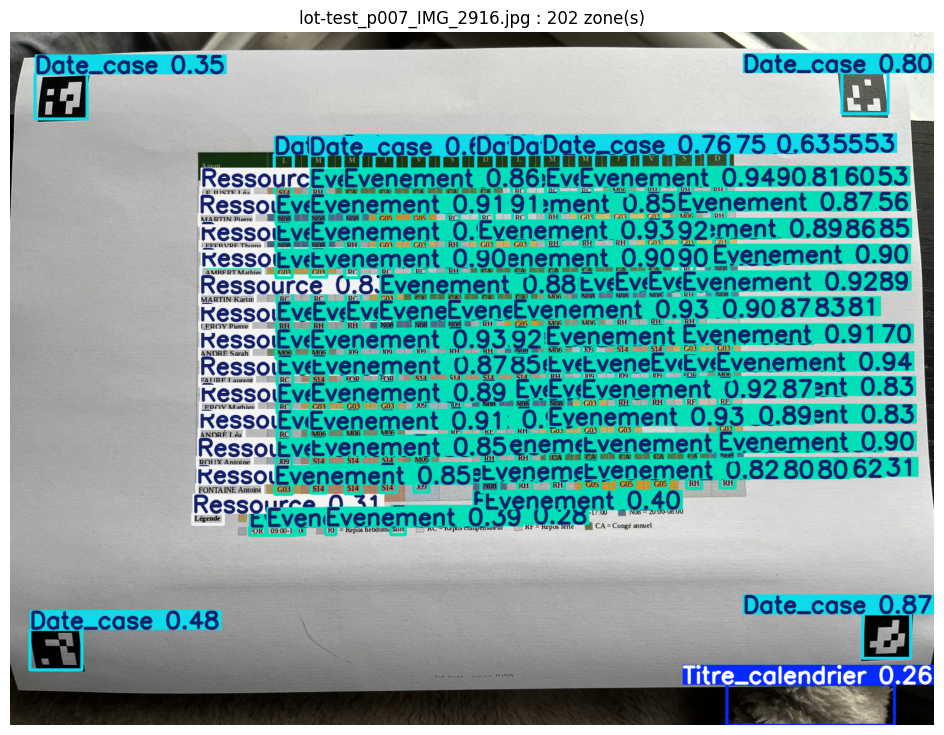

,classe,confiance_detection,x1,y1,x2,y2,texte,confiance_ocr,lignes_ignorees
128,Date_case,0.803,1440,70,1520,141,,NaN,1
192,Date_case,0.349,43,72,133,150,,NaN,1
184,Date_case,0.530,1204,208,1243,247,D 2211,0.846,0
172,Date_case,0.629,1092,209,1126,246,V 2011,0.934,0
180,Date_case,0.554,1149,209,1183,247,5 2111,0.804,0
...,...,...,...,...,...,...,...,...,...
197,Evenement,0.283,414,857,442,871,FOR,1.000,0
193,Evenement,0.333,491,857,510,870,7.0,0.537,0
70,Date_case,0.866,1476,1007,1559,1084,4,0.557,0
186,Date_case,0.480,34,1034,124,1104,,NaN,0


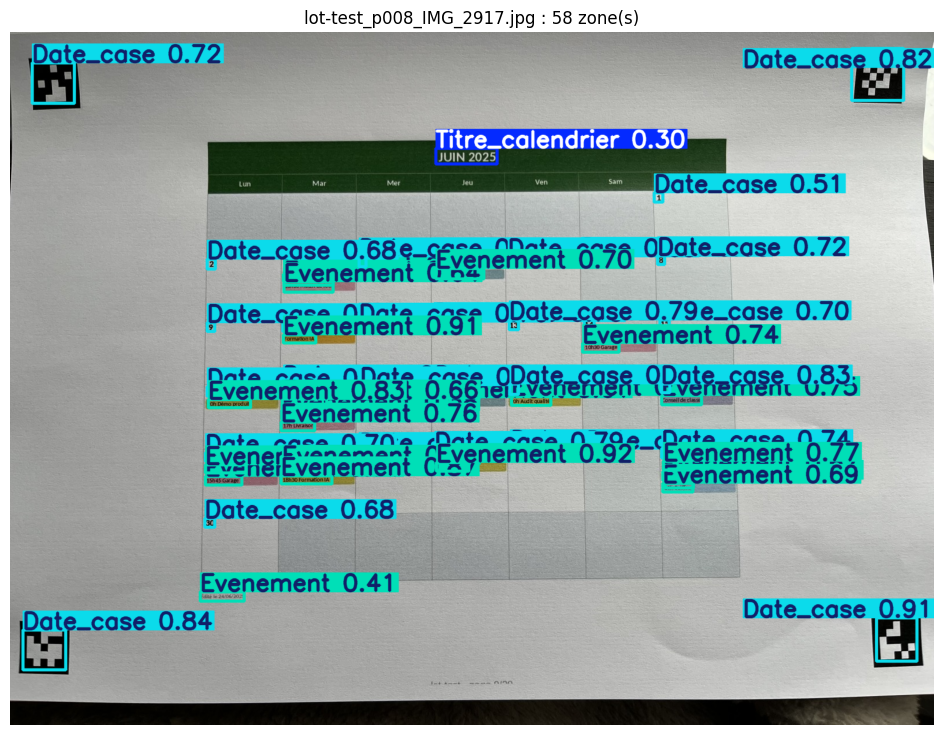

,classe,confiance_detection,x1,y1,x2,y2,texte,confiance_ocr,lignes_ignorees
7,Date_case,0.824,1457,28,1547,118,,NaN,0
21,Date_case,0.724,38,53,111,123,,NaN,1
55,Titre_calendrier,0.297,737,201,843,228,JUIN 2025,0.712,0
47,Date_case,0.508,1115,278,1130,294,1,1.000,0
22,Date_case,0.719,1121,387,1133,402,8,1.000,0
40,Date_case,0.629,989,388,1003,403,7,1.000,0
36,Date_case,0.669,604,389,616,406,4,0.999,0
56,Date_case,0.281,729,389,744,405,5,1.000,0
54,Date_case,0.342,733,389,750,407,5,1.000,0
28,Date_case,0.688,862,389,873,406,6,1.000,0


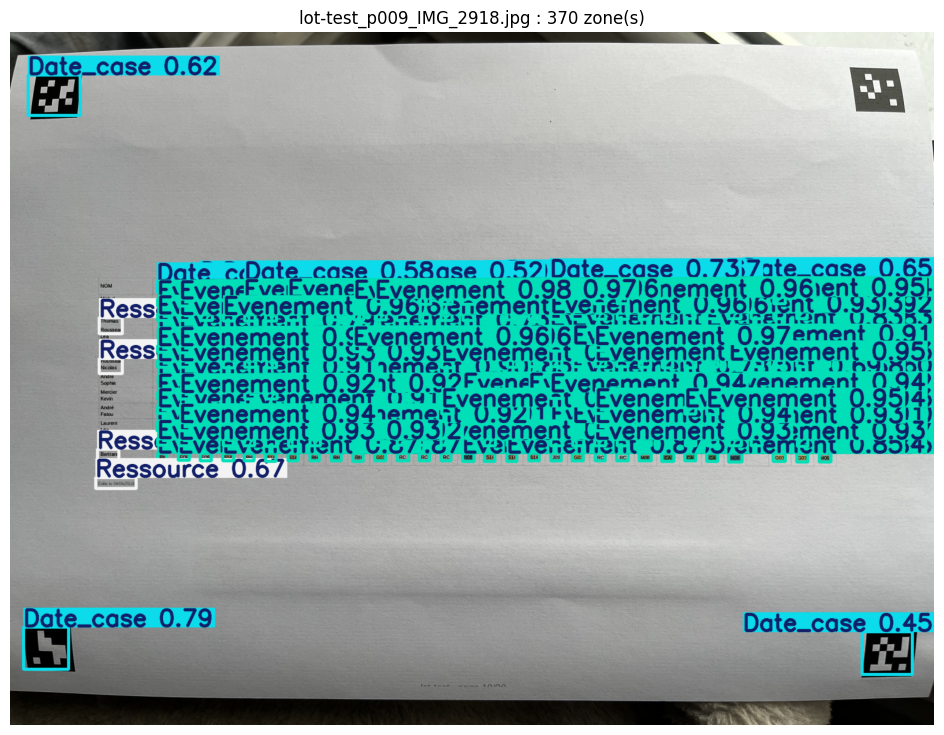

,classe,confiance_detection,x1,y1,x2,y2,texte,confiance_ocr,lignes_ignorees
311,Date_case,0.624,31,74,121,144,4,0.758,0
332,Date_case,0.537,1400,423,1423,451,D [9/07,0.634,0
339,Date_case,0.492,1243,424,1264,446,M 15/07,0.718,0
304,Date_case,0.653,1360,424,1381,448,5 18/07,0.726,0
284,Date_case,0.731,935,425,952,448,M,0.968,1
...,...,...,...,...,...,...,...,...,...
238,Evenement,0.828,1362,729,1381,744,,NaN,1
232,Evenement,0.831,1401,729,1421,744,Mos,0.438,0
299,Ressource,0.669,148,771,218,790,,NaN,1
264,Date_case,0.795,23,1030,101,1103,,NaN,0


In [9]:
import matplotlib.pyplot as plt
import pandas as pd

EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
chemin = Path(IMAGES)
if chemin.is_dir():
    images = sorted(p for p in chemin.iterdir() if p.suffix.lower() in EXTENSIONS)
else:
    images = [chemin]
images = images[:MAX_IMAGES]
print(f"{len(images)} image(s) à traiter")

toutes_les_lignes = []  # une ligne par zone détectée, toutes images confondues
resultats_json = []     # même contenu, regroupé par image (pour le fichier JSON)

for image_path in images:
    result = model.predict(str(image_path), conf=CONF, imgsz=640, max_det=1000, verbose=False)[0]
    img = result.orig_img  # image d'origine en BGR (numpy)
    h_img, w_img = img.shape[:2]

    lignes = []
    for box in result.boxes:
        x1, y1, x2, y2 = (int(v) for v in box.xyxy[0].tolist())
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(w_img, x2), min(h_img, y2)
        if x2 <= x1 or y2 <= y1:
            continue
        classe = model.names[int(box.cls)]
        if CLASSES_OCR is None or classe in CLASSES_OCR:
            # Découpe exacte de la boîte (bornée à l'image), comme dans l'application
            texte, conf_ocr, nb_ignorees = lire_zone(img[y1:y2, x1:x2])
        else:
            texte, conf_ocr, nb_ignorees = "", None, 0  # classe exclue de l'OCR
        lignes.append({
            "image": image_path.name,
            "classe": classe,
            "confiance_detection": round(float(box.conf), 3),
            "x1": x1, "y1": y1, "x2": x2, "y2": y2,
            "texte": texte,
            "confiance_ocr": conf_ocr,
            "lignes_ignorees": nb_ignorees,
        })

    # Affichage : image annotée (plot() renvoie du BGR → conversion en RGB)
    plt.figure(figsize=(12, 9))
    plt.imshow(cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB))
    plt.title(f"{image_path.name} : {len(lignes)} zone(s)")
    plt.axis("off")
    plt.show()

    if lignes:
        df_image = pd.DataFrame(lignes).sort_values(["y1", "x1"])
        display(df_image.drop(columns="image"))
    else:
        print("Aucune zone détectée : essayez de baisser CONF.")

    toutes_les_lignes.extend(lignes)
    resultats_json.append({"image": image_path.name, "largeur": w_img, "hauteur": h_img,
                           "zones": [{k: v for k, v in l.items() if k != "image"} for l in lignes]})

## 7. Résumé par classe

Pour chaque classe : nombre de zones, part des zones où l'OCR n'a rien lu, confiance OCR moyenne,
nombre de lignes ignorées (confiance < `OCR_MIN_CONF`) et quelques exemples de textes lus.
Beaucoup de lignes ignorées ? Essayez de baisser `OCR_MIN_CONF` pour voir ce que l'OCR « devine ».

In [10]:
df = pd.DataFrame(toutes_les_lignes)
if df.empty:
    print("Aucune zone détectée sur ces images.")
else:
    resume = df.groupby("classe").agg(
        nb_zones=("texte", "size"),
        part_texte_vide=("texte", lambda s: round((s == "").mean(), 2)),
        confiance_ocr_moyenne=("confiance_ocr", lambda s: round(s.mean(), 3)),
        lignes_ignorees=("lignes_ignorees", "sum"),
        exemples=("texte", lambda s: [t for t in s if t][:3]),
    )
    display(resume)
    print(f"Lignes OCR ignorées (confiance < {OCR_MIN_CONF}) : {int(df['lignes_ignorees'].sum())}")

,nb_zones,part_texte_vide,confiance_ocr_moyenne,lignes_ignorees,exemples
classe,,,,,
Date_case,223,0.19,0.901,46,"[Jeudi 22/10, SAMEDI 24/10, VENDREDI 23/10]"
Evenement,693,0.25,0.724,186,"[8h30à 17h30 Entepôt Nord, 8h30 à 17h30 Entrep..."
Ressource,40,0.02,0.861,3,"[Mme Moreau, Mme Fontaine, M. Ferreira]"
Titre_calendrier,9,0.11,0.779,0,"[PLANNING SEMAINE 43, Planning du 22 novembre ..."


Lignes OCR ignorées (confiance < 0.4) : 235


## 8. Sauvegarde des résultats

Le fichier `ocr_<alias>.json` contient, image par image, les zones détectées et le texte lu.
Téléchargez-le (panneau *Fichiers* de Colab) : il vous servira à écrire et tester votre parser
**sans relancer** le modèle ni l'OCR.

In [11]:
sortie = Path(f"ocr_{ALIAS}.json")
with open(sortie, "w", encoding="utf-8") as f:
    json.dump({"modele": f"{MODEL_NAME}@{ALIAS}", "version": version.version,
               "classes": {int(k): v for k, v in model.names.items()},
               "images": resultats_json}, f, ensure_ascii=False, indent=2)
print("Résultats sauvegardés dans", sortie)

Résultats sauvegardés dans ocr_champion.json


## 9. Pistes pour le parsing

Pas de solution ici : des questions pour préparer le jour 3. Notez vos réponses dans vos livrables.

- **Qui porte quoi ?** Avec **vos** classes, laquelle contient la date (le numéro du jour, le mois) ?
  l'heure ? le titre de l'événement ? Certaines classes sont-elles inutiles pour le parsing ?
- **Relier un événement à son jour** : comment savoir à quel jour appartient une zone « événement » ?
  Regardez les coordonnées `x1, y1, x2, y2` : une zone est-elle *contenue* dans une autre ?
  Sur la même ligne, la même colonne qu'un en-tête ?
- **Formats d'heure** : quels formats apparaissent dans vos images (`8h30`, `08:30`, `8h-12h`, `14h00 - 18h`…) ?
  Quelle expression régulière les couvrirait tous ?
- **Confusions de l'OCR** : repérez-vous des lettres à la place de chiffres (`O` → `0`, `I`/`l` → `1`, `S` → `5`) ?
  Dans quels cas peut-on les corriger sans risque ?
- **Texte vide ou peu sûr** : que faire d'une zone sans texte, ou lue avec une confiance faible ?
  L'application CalEvent attribue une confiance à chaque événement extrait et l'utilise ainsi :
  **≥ 0,8 pré-coché**, **0,5 – 0,8 à vérifier**, **< 0,5 non proposé**.
  Comment calculeriez-vous cette confiance (détection, OCR, parsing réussi ou non) ?
- **Rappel avant tout** : une zone ratée par le modèle, c'est un créneau perdu. Quelles zones manquent
  sur les images ci-dessus ?

## 10. Comparer avec le challenger

Au jour 2, une fois un modèle `challenger` enregistré :

1. remplacez `ALIAS = "champion"` par `ALIAS = "challenger"` dans les paramètres ;
2. relancez tout le notebook (*Exécution → Tout exécuter*) : les résultats vont dans `ocr_challenger.json` ;
3. comparez les deux résumés par classe : nombre de zones, part de textes vides, confiance OCR.
4. comparez les métriques `test/*` des deux runs dans MLflow (section 11).

Critère de promotion : **le rappel d'abord**, la mAP50 pour départager, et un coup d'œil à l'OCR
(un modèle qui découpe mieux les zones donne un texte plus propre). C'est le ou la **lead** de la squad
qui décide de déplacer l'alias `champion`.

## 11. Métriques sur votre jeu de test noté

L'OCR ci-dessus montre **ce qui est lu**. Pour décider d'une promotion, il faut aussi **mesurer** la détection
sur de vraies photos annotées : c'est le rôle du jeu de test noté de votre squad, `<squad>.zip` (donné par
l'intervenant ; à déposer dans Colab, panneau *Fichiers*). Ce sont des photos de plannings imprimés, jamais vues
à l'entraînement, annotées avec **vos** classes, dans l'ordre de votre `data.yaml`.

Pourquoi pas les métriques de `val` ? Dès le dataset `v2`, `val` contient des images simulées, plus faciles que
vos photos : le rappel y est flatteur.

La cellule calcule le rappel, la précision et la mAP50 du modèle `ALIAS`, le rappel **par classe** (où le
modèle rate-t-il ?), puis les range dans le run du modèle sous `test/recall`, `test/precision` et `test/mAP50`.
Relancez-la avec `ALIAS = "challenger"` : dans MLflow, *Compare* met alors les deux modèles côte à côte
sur les **mêmes** photos.

In [13]:
import zipfile

import yaml

# Jeu de test noté de la squad : <squad>.zip (dossier test_<squad>/ à l'intérieur)
zips = [Path(f"{SQUAD}.zip"), Path(f"test_{SQUAD}.zip")]
test_dir = Path(f"test_{SQUAD}")
if not test_dir.is_dir():
    zip_test = next((z for z in zips if z.exists()), None)
    if zip_test is None:
        raise FileNotFoundError(f"Déposez {zips[0]} (jeu de test noté de la squad) dans Colab, panneau Fichiers.")
    with zipfile.ZipFile(zip_test) as z:
        z.extractall(".")
data_test = test_dir / "data.yaml"

# best.pt du run de la version testée (le même fichier que l'ONNX, avant export)
pt_path = Path(mlflow.artifacts.download_artifacts(run_id=version.run_id, artifact_path="best.pt",
                                                   dst_path=f"modele_{ALIAS}_pt"))
modele_pt = YOLO(str(pt_path))

# Les identifiants des classes doivent correspondre, sinon les métriques ne veulent rien dire
noms_test = yaml.safe_load(data_test.read_text())["names"]
noms_test = [noms_test[i] for i in sorted(noms_test)] if isinstance(noms_test, dict) else list(noms_test)
noms_modele = [modele_pt.names[i] for i in sorted(modele_pt.names)]
assert noms_test == noms_modele, (
    f"Classes différentes : modèle {noms_modele}, jeu de test {noms_test}. "
    "Prévenez l'intervenant (ordre des classes du data.yaml).")

# Même taille d'image qu'à l'entraînement (paramètre imgsz du run)
imgsz = int(client.get_run(version.run_id).data.params.get("imgsz", 640))
m = modele_pt.val(data=str(data_test), split="test", imgsz=imgsz, plots=False, verbose=False)

print(f"{MODEL_NAME}@{ALIAS} (version {version.version}), {len(list((test_dir / 'images' / 'test').glob('*')))} photos")
print(f"  rappel {m.box.mr:.3f}   précision {m.box.mp:.3f}   mAP50 {m.box.map50:.3f}\n")
print("Rappel par classe :")
presentes = list(m.box.ap_class_index)
for i, nom in enumerate(noms_modele):
    print(f"  {nom:28} " + (f"{m.box.r[presentes.index(i)]:.3f}" if i in presentes else "absente du jeu de test"))

# Rangées dans le run du modèle, sans le rouvrir (MLflow réécrirait sa date de fin)
mlflow.log_metrics({"test/recall": float(m.box.mr), "test/precision": float(m.box.mp),
                    "test/mAP50": float(m.box.map50)}, run_id=version.run_id)
print(f"\nMétriques test/* enregistrées dans le run « {run_name} ».")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2476.0±560.7 MB/s, size: 423.9 KB)
val: Scanning /content/test_team-rocket/labels/test... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 1.2Kit/s 0.0s
val: New cache created: /content/test_team-rocket/labels/test.cache
WARNING ⚠️ Dataset images contain up to 373 objects (test=373), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=373 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.2it/s 0.9s
                   all         20       1298      0.635      0.736      0.606      0.181
Speed: 0.8ms preprocess, 10.

## 12. Bonus : `best.pt` ou `model.onnx` ? (sur CPU)

Votre run contient deux versions du même modèle : `best.pt` (PyTorch, pour entraîner) et `model.onnx`
(pour déployer). CalEvent sert l'**ONNX sur CPU, sans PyTorch**. Est-ce vraiment mieux ? On mesure, au lieu de le croire :

| Mesure | Pourquoi |
|---|---|
| **taille du fichier** | à télécharger, à embarquer dans une app mobile |
| **temps de chargement** | démarrage du service, rechargement à chaud (↻) |
| **temps d'inférence** (médiane, ms / image) | ce que l'utilisateur attend |
| **mémoire maximale** du processus | ce que coûte le serveur (la VM est partagée) |
| **mêmes détections ?** | l'export ne doit rien changer au résultat |

Trois façons de lancer le modèle, chacune dans **son propre processus** Python (sinon la mémoire de l'une
pollue la mesure de l'autre) :

- `pt` : `best.pt` avec Ultralytics (PyTorch) ;
- `onnx` : `model.onnx` avec Ultralytics (onnxruntime derrière, mais PyTorch est quand même importé) ;
- `ort` : `model.onnx` avec **onnxruntime seul**, comme dans CalEvent (ni PyTorch ni Ultralytics ;
  on mesure l'inférence brute, sans le post-traitement).

Tout tourne sur **CPU** (même si Colab a un GPU) : c'est la situation du serveur de déploiement.
Les chiffres dépendent de la machine (un Colab gratuit a 2 cœurs) : comparez-les **entre eux**, sur la même machine.

In [ ]:
# Récupère best.pt dans le run de la version testée (il y a été loggé avec mlflow.log_artifact)
pt_path = Path(mlflow.artifacts.download_artifacts(run_id=version.run_id, artifact_path="best.pt",
                                                   dst_path=f"modele_{ALIAS}_pt"))
print("best.pt :", pt_path)

N_REPET = 5            # passages par image (le premier, à froid, est écarté)
images_bench = [str(p) for p in images[:5]]  # 5 images suffisent pour un ordre de grandeur


In [ ]:
import subprocess
import sys

# Script de mesure, lancé dans un processus neuf pour chaque façon de faire
Path("mesure_inference.py").write_text(r"""
import json, resource, sys, time
mode, chemin, n_repet, conf = sys.argv[1], sys.argv[2], int(sys.argv[3]), float(sys.argv[4])
images = json.loads(sys.argv[5])
import cv2
import numpy as np

t0 = time.perf_counter()
if mode == "ort":
    import onnxruntime as ort
    sess = ort.InferenceSession(chemin, providers=["CPUExecutionProvider"])
    entree = sess.get_inputs()[0]
    h, w = (d if isinstance(d, int) else 640 for d in entree.shape[2:4])
    def inferer(p):
        img = cv2.resize(cv2.imread(p), (w, h))[:, :, ::-1]  # BGR -> RGB
        x = np.ascontiguousarray(img.transpose(2, 0, 1)[None], dtype=np.float32) / 255.0
        sess.run(None, {entree.name: x})
        return None  # sortie brute : pas de NMS, donc pas de nombre de boîtes
else:
    from ultralytics import YOLO
    model = YOLO(chemin, task="detect")
    def inferer(p):
        r = model.predict(p, conf=conf, imgsz=640, max_det=1000, device="cpu", verbose=False)[0]
        return len(r.boxes)
    inferer(images[0])  # premier appel : charge réellement le modèle (ONNX)
chargement = time.perf_counter() - t0

durees, boites = [], []
for p in images:
    boites.append(inferer(p))          # passage à froid, écarté
    for _ in range(n_repet):
        t = time.perf_counter()
        inferer(p)
        durees.append((time.perf_counter() - t) * 1000)

print(json.dumps({
    "chargement_s": round(chargement, 2),
    "inference_ms_mediane": round(float(np.median(durees)), 1),
    "memoire_max_mo": round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024),  # Linux : ko
    "boites": boites,
}))
""")

mesures = {}
for mode, chemin in [("pt", pt_path), ("onnx", onnx_path), ("ort", onnx_path)]:
    sortie = subprocess.run([sys.executable, "mesure_inference.py", mode, str(chemin), str(N_REPET), str(CONF),
                             json.dumps(images_bench)], capture_output=True, text=True)
    if sortie.returncode != 0:
        print(f"{mode} : échec\n", sortie.stderr[-1500:])
        continue
    mesures[mode] = json.loads(sortie.stdout.strip().splitlines()[-1])
    mesures[mode]["taille_mo"] = round(Path(chemin).stat().st_size / 1e6, 1)
    print(mode, "OK")


In [ ]:
tableau = pd.DataFrame(mesures).T[["taille_mo", "chargement_s", "inference_ms_mediane", "memoire_max_mo"]]
tableau.index = tableau.index.map({"pt": "best.pt (PyTorch)", "onnx": "model.onnx (Ultralytics)",
                                   "ort": "model.onnx (onnxruntime seul, comme CalEvent)"})
display(tableau)

# L'export a-t-il changé les détections ? (même seuil CONF, mêmes images)
if "pt" in mesures and "onnx" in mesures:
    for img, n_pt, n_onnx in zip(images_bench, mesures["pt"]["boites"], mesures["onnx"]["boites"]):
        marque = "" if n_pt == n_onnx else "  <-- différent"
        print(f"{Path(img).name:<30} best.pt : {n_pt:>3} boîtes | ONNX : {n_onnx:>3} boîtes{marque}")


**À noter dans vos livrables** (note de synthèse, partie déploiement) :

- Quel format est le plus **léger** ? le plus **rapide** ? lequel consomme le moins de **mémoire**, et pourquoi
  (indice : regardez ce que chaque processus doit importer) ?
- Les détections sont-elles identiques ? Un petit écart peut venir des arrondis de calcul ; un gros écart
  signale un problème d'export (taille d'image, version d'opset…).
- Si le serveur de déploiement avait 1 Go de mémoire libre, lequel choisiriez-vous ? Et pour une application
  **mobile** sans connexion ?
- Ces chiffres sont-ils valables sur la VM du cours ? Qu'est-ce qui changerait (nombre de cœurs, GPU absent) ?
